# Exercise 7 - Clustering pada Hasil Feature Engineering

 Try applying all clustering methods on the text you have feature engineering from the previous exercise and analyze the given results.


In [3]:
import warnings
warnings.filterwarnings("ignore")

## 0. Install library

In [4]:
!pip install gensim wordcloud -q

## 1. Import Data



In [5]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/feature enginering

Mounted at /content/drive
/content/drive/MyDrive/feature enginering


In [6]:
NAMA_CSV    = 'hasil prepocesssing 2 (1).csv'
KOLOM_TEKS  = 'prepro'
FILE_W2V    = 'review_produk.w2v'
FILE_FT     = 'review_produk.fasttext'

LATIH_ULANG = False

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv(NAMA_CSV)
print('Kolom yang tersedia:', list(df.columns))
df = df.dropna(subset=[KOLOM_TEKS]).reset_index(drop=True)
df[KOLOM_TEKS] = df[KOLOM_TEKS].astype(str)
df_pre = df[KOLOM_TEKS]
print('Jumlah data:', len(df))
df.head()

Kolom yang tersedia: ['Id', 'Sentiment', 'text', 'prepro']
Jumlah data: 1998


,Id,Sentiment,text,prepro
0,A000044,Positive,kalo soal kemeja top dah erigo. 🤝,kemeja top dah erigo 🤝
1,A000114,Positive,"Bahannya adem ya, halus lagi XL ny besar bgtz ...",bahan adem iya halus xl ny bgtz moga pas pakai...
2,A000202,Positive,"Bahannya enak banget, adem. Oversized dikit bu...",bahan enak banget adem oversized dikit bb 83kg...
3,A000224,Positive,bahan adem dan nyaman ini keren sih,bahan adem nyaman keren sih
4,A000242,Positive,"Tinggi badan 165, berat badan 75, serasa memak...",badan 165 berat badan 75 serasa pakai kemeja o...


## 2. Feature Engineering

###  change text to number

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_tfidf = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
print('Shape TF-IDF:', df_tfidf.shape)

Shape TF-IDF: (1998, 2830)


### 2.2 Word2Vec dan 2.3 FastText

In [9]:
from gensim.models import Word2Vec, FastText, KeyedVectors

tokens = [t.split() for t in df_pre]

def muat_model(path, kelas):
    try:
        return kelas.load(path).wv
    except Exception:
        return KeyedVectors.load(path)

if LATIH_ULANG:
    w2v_wv = Word2Vec(tokens, vector_size=100, window=5, min_count=1, seed=42).wv
    ft_wv  = FastText(tokens, vector_size=100, window=5, min_count=1, seed=42).wv
else:
    w2v_wv = muat_model(FILE_W2V, Word2Vec)
    ft_wv  = muat_model(FILE_FT, FastText)

print('Dimensi Word2Vec:', w2v_wv.vector_size, '| kosakata:', len(w2v_wv.key_to_index))
print('Dimensi FastText :', ft_wv.vector_size, '| kosakata:', len(ft_wv.key_to_index))

Dimensi Word2Vec: 100 | kosakata: 3043
Dimensi FastText : 100 | kosakata: 3043


In [10]:
def vektor_review(kata_list, wv, pakai_oov=False):
    vec = []
    for k in kata_list:
        if k in wv.key_to_index or pakai_oov:
            vec.append(wv[k])
    return np.mean(vec, axis=0) if vec else np.zeros(wv.vector_size)

df_w2v = pd.DataFrame([vektor_review(t, w2v_wv) for t in tokens])
df_ft  = pd.DataFrame([vektor_review(t, ft_wv, pakai_oov=True) for t in tokens])

for nama, F in [('Word2Vec', df_w2v), ('FastText', df_ft)]:
    nol = int((F.abs().sum(axis=1) == 0).sum())
    print(f'{nama}: {nol} review bervektor nol dari {len(F)}')

fitur = {'TFIDF': df_tfidf, 'Word2Vec': df_w2v, 'FastText': df_ft}

Word2Vec: 0 review bervektor nol dari 1998
FastText: 0 review bervektor nol dari 1998


## 3. Unsupervised: KMeans

Run on all three feature engineering results. Start with the **elbow method** to determine the number of clusters.

In [11]:
from sklearn.cluster import KMeans
from wordcloud import WordCloud

In [12]:
k = range(1, 7)
inertia_semua = {}

for nama, F in fitur.items():
    inertia = []
    for i in k:
        km_model = KMeans(n_clusters=i, random_state=10)  # jumlah cluster akan di looping
        km_model.fit(F)
        inertia.append(km_model.inertia_)
    inertia_semua[nama] = inertia
    print(nama, [round(v, 2) for v in inertia])

TFIDF [1939.27, 1913.67, 1898.23, 1862.32, 1854.48, 1838.71]
Word2Vec [559.34, 226.53, 118.13, 68.74, 43.13, 31.82]
FastText [204.24, 150.15, 108.87, 90.39, 79.25, 69.71]


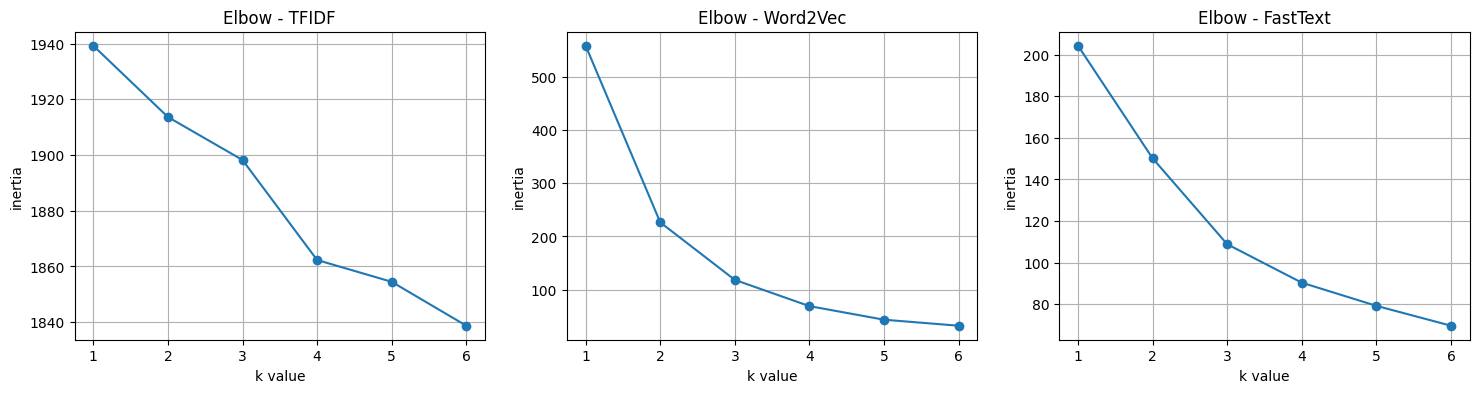

In [13]:
plt.figure(figsize=(18, 4))
for idx, (nama, inertia) in enumerate(inertia_semua.items(), 1):
    plt.subplot(1, 3, idx)
    plt.plot(k, inertia, marker='o')
    plt.title('Elbow - ' + nama)
    plt.xlabel('k value')
    plt.ylabel('inertia')
    plt.grid()
plt.show()

In [14]:
n_clusters = 3

In [15]:
from sklearn import metrics

hasil = []
for nama, F in fitur.items():
    kM = KMeans(n_clusters=n_clusters, random_state=10).fit(F)
    df['Kmeans_' + nama] = kM.labels_
    sil = metrics.silhouette_score(F, kM.labels_, metric='euclidean')
    hasil.append({'Fitur': nama, 'Metode': 'KMeans', 'Silhouette': sil,
                  'Davies-Bouldin': metrics.davies_bouldin_score(F, kM.labels_)})

df.head()

,Id,Sentiment,text,prepro,Kmeans_TFIDF,Kmeans_Word2Vec,Kmeans_FastText
0,A000044,Positive,kalo soal kemeja top dah erigo. 🤝,kemeja top dah erigo 🤝,0,2,2
1,A000114,Positive,"Bahannya adem ya, halus lagi XL ny besar bgtz ...",bahan adem iya halus xl ny bgtz moga pas pakai...,0,1,2
2,A000202,Positive,"Bahannya enak banget, adem. Oversized dikit bu...",bahan enak banget adem oversized dikit bb 83kg...,2,1,2
3,A000224,Positive,bahan adem dan nyaman ini keren sih,bahan adem nyaman keren sih,0,0,0
4,A000242,Positive,"Tinggi badan 165, berat badan 75, serasa memak...",badan 165 berat badan 75 serasa pakai kemeja o...,0,1,2


**Silhouette Score (KMeans)**

In [16]:
tabel_km = pd.DataFrame(hasil)
tabel_km.round(4)

,Fitur,Metode,Silhouette,Davies-Bouldin
0,TFIDF,KMeans,0.0065,5.9131
1,Word2Vec,KMeans,0.5166,0.5995
2,FastText,KMeans,0.2847,1.1821


**Ukuran tiap cluster (KMeans)**

In [17]:
for nama in fitur:
    print('Kmeans', nama)
    print(df['Kmeans_' + nama].value_counts().sort_index().to_string())
    print()

Kmeans TFIDF
Kmeans_TFIDF
0    1600
1     195
2     203

Kmeans Word2Vec
Kmeans_Word2Vec
0    644
1    989
2    365

Kmeans FastText
Kmeans_FastText
0    649
1    808
2    541



**Word Cloud (KMeans)**

Kmeans_TFIDF - cluster 0


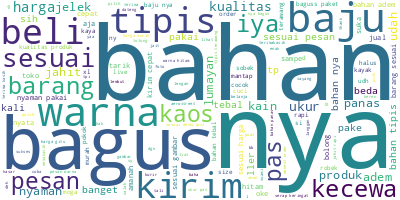

Kmeans_TFIDF - cluster 1


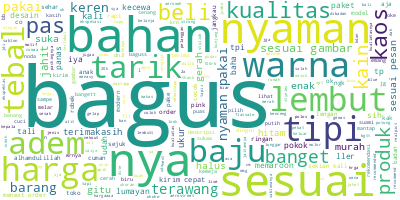

Kmeans_TFIDF - cluster 2


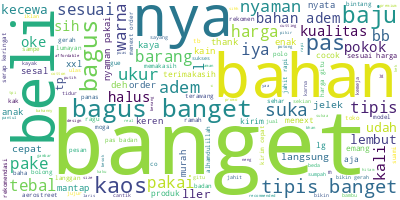

In [18]:
def tampil_wordcloud(kolom_label, c):
    print(kolom_label + ' - cluster ' + str(c))
    df_c = df[df[kolom_label] == c]
    long_string = ','.join(list(df_c[KOLOM_TEKS].values))
    wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
    wordcloud.generate(long_string)
    display(wordcloud.to_image())

# KMeans + TF-IDF
for c in range(n_clusters):
    tampil_wordcloud('Kmeans_TFIDF', c)

Kmeans_Word2Vec - cluster 0


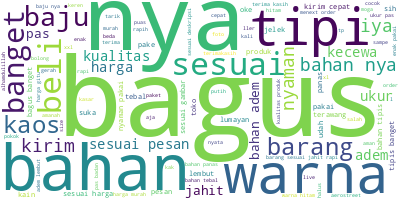

Kmeans_Word2Vec - cluster 1


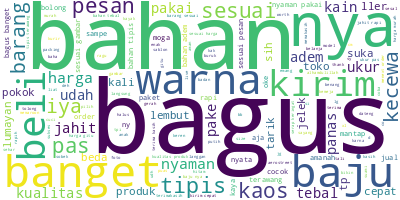

Kmeans_Word2Vec - cluster 2


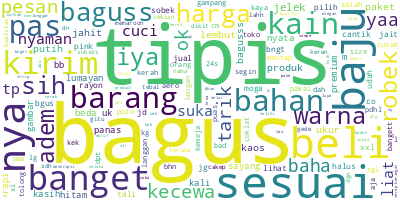

In [19]:
# KMeans + Word2Vec
for c in range(n_clusters):
    tampil_wordcloud('Kmeans_Word2Vec', c)

Kmeans_FastText - cluster 0


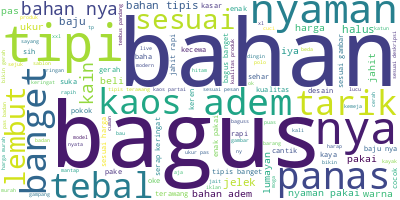

Kmeans_FastText - cluster 1


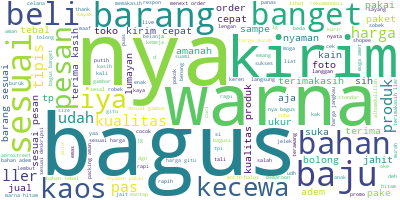

Kmeans_FastText - cluster 2


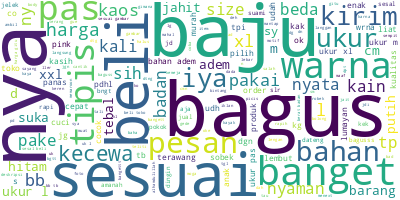

In [20]:
# KMeans + FastText
for c in range(n_clusters):
    tampil_wordcloud('Kmeans_FastText', c)

## 4. Unsupervised: Hierarchical

In [21]:
from scipy.cluster.hierarchy import dendrogram, linkage

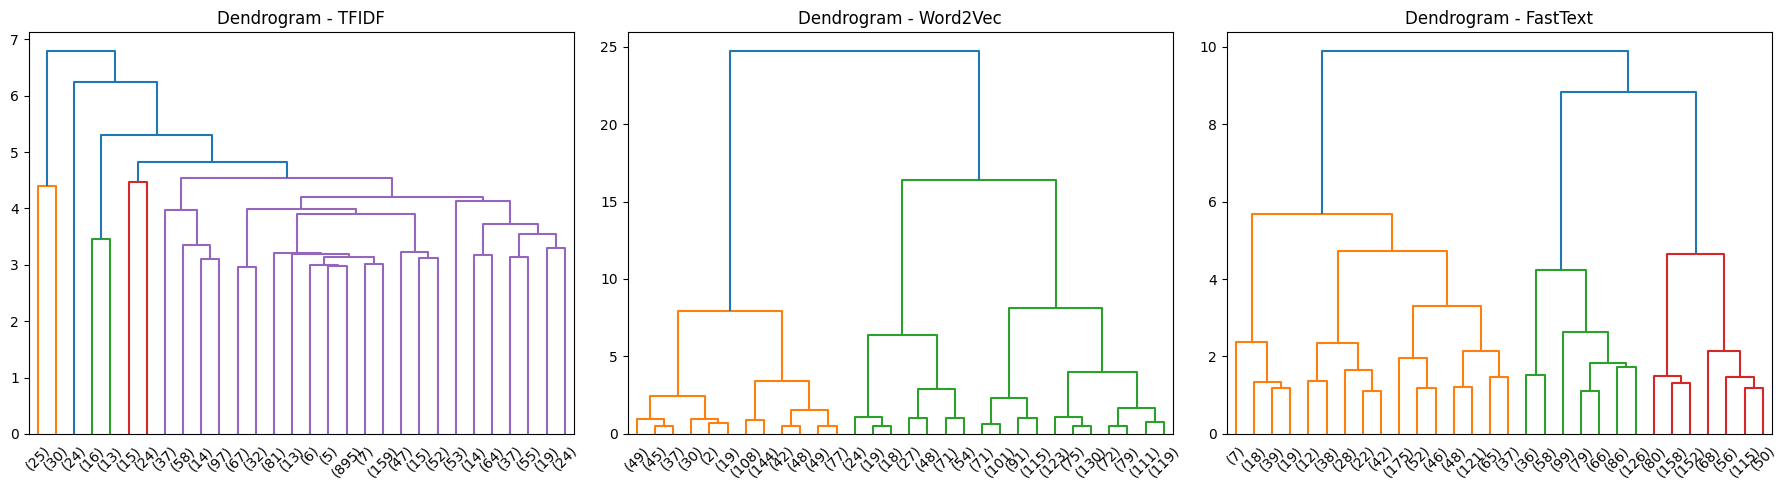

In [22]:
plt.figure(figsize=(18, 5))
for idx, (nama, F) in enumerate(fitur.items(), 1):
    linkage_data = linkage(F, method='ward', metric='euclidean')
    plt.subplot(1, 3, idx)

    dendrogram(linkage_data, truncate_mode='lastp', p=30)
    plt.title('Dendrogram - ' + nama)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.cluster import AgglomerativeClustering

hasil_hc = []
for nama, F in fitur.items():
    hierarchical_cluster = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    hierarchical_cluster.fit(F)
    df['Ward_' + nama] = pd.Series(hierarchical_cluster.labels_)
    sil = metrics.silhouette_score(F, hierarchical_cluster.labels_, metric='euclidean')
    hasil_hc.append({'Fitur': nama, 'Metode': 'Hierarchical (Ward)', 'Silhouette': sil,
                     'Davies-Bouldin': metrics.davies_bouldin_score(F, hierarchical_cluster.labels_)})
df.head()

,Id,Sentiment,text,prepro,Kmeans_TFIDF,Kmeans_Word2Vec,Kmeans_FastText,Ward_TFIDF,Ward_Word2Vec,Ward_FastText
0,A000044,Positive,kalo soal kemeja top dah erigo. 🤝,kemeja top dah erigo 🤝,0,2,2,0,2,0
1,A000114,Positive,"Bahannya adem ya, halus lagi XL ny besar bgtz ...",bahan adem iya halus xl ny bgtz moga pas pakai...,0,1,2,0,0,0
2,A000202,Positive,"Bahannya enak banget, adem. Oversized dikit bu...",bahan enak banget adem oversized dikit bb 83kg...,2,1,2,0,0,0
3,A000224,Positive,bahan adem dan nyaman ini keren sih,bahan adem nyaman keren sih,0,0,0,0,1,1
4,A000242,Positive,"Tinggi badan 165, berat badan 75, serasa memak...",badan 165 berat badan 75 serasa pakai kemeja o...,0,1,2,0,0,0


**Silhouette Score (Hierarchical)**

In [24]:
tabel_hc = pd.DataFrame(hasil_hc)
tabel_hc.round(4)

,Fitur,Metode,Silhouette,Davies-Bouldin
0,TFIDF,Hierarchical (Ward),-0.0127,2.1499
1,Word2Vec,Hierarchical (Ward),0.5200,0.5817
2,FastText,Hierarchical (Ward),0.2528,1.2257


**Ukuran tiap cluster (Hierarchical)**

In [25]:
for nama in fitur:
    print('Ward', nama)
    print(df['Ward_' + nama].value_counts().sort_index().to_string())
    print()

Ward TFIDF
Ward_TFIDF
0    1919
1      55
2      24

Ward Word2Vec
Ward_Word2Vec
0    1087
1     650
2     261

Ward FastText
Ward_FastText
0    769
1    679
2    550



**Word Cloud (Hierarchical)**

Ward_TFIDF - cluster 0


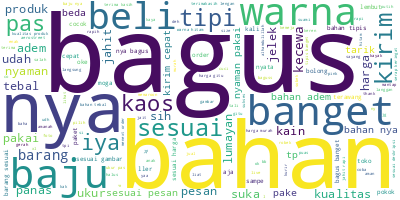

Ward_TFIDF - cluster 1


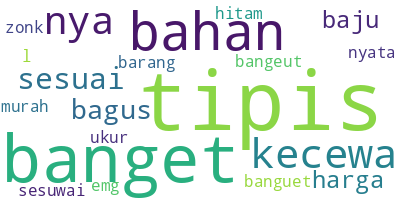

Ward_TFIDF - cluster 2


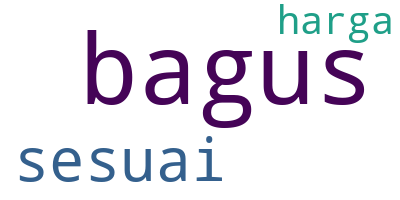

In [26]:
# Hierarchical + TF-IDF
for c in range(n_clusters):
    tampil_wordcloud('Ward_TFIDF', c)

Ward_Word2Vec - cluster 0


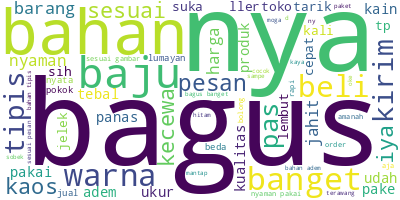

Ward_Word2Vec - cluster 1


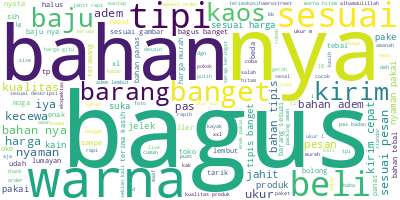

Ward_Word2Vec - cluster 2


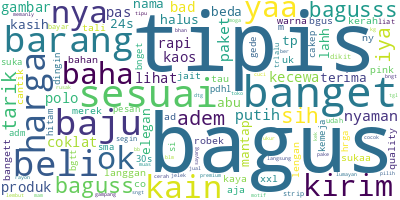

In [27]:
# Hierarchical + Word2Vec
for c in range(n_clusters):
    tampil_wordcloud('Ward_Word2Vec', c)

Ward_FastText - cluster 0


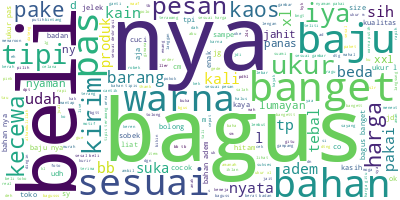

Ward_FastText - cluster 1


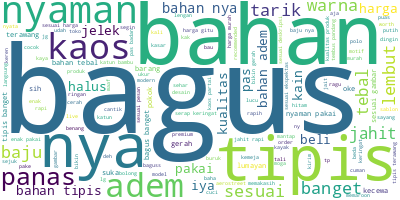

Ward_FastText - cluster 2


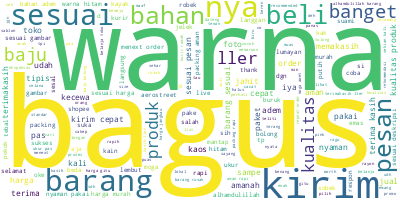

In [28]:
# Hierarchical + FastText
for c in range(n_clusters):
    tampil_wordcloud('Ward_FastText', c)

## 5. Perbandingan Hasil

,Fitur,Metode,Silhouette,Davies-Bouldin
0,Word2Vec,Hierarchical (Ward),0.5200,0.5817
1,Word2Vec,KMeans,0.5166,0.5995
2,FastText,KMeans,0.2847,1.1821
3,FastText,Hierarchical (Ward),0.2528,1.2257
4,TFIDF,KMeans,0.0065,5.9131
5,TFIDF,Hierarchical (Ward),-0.0127,2.1499


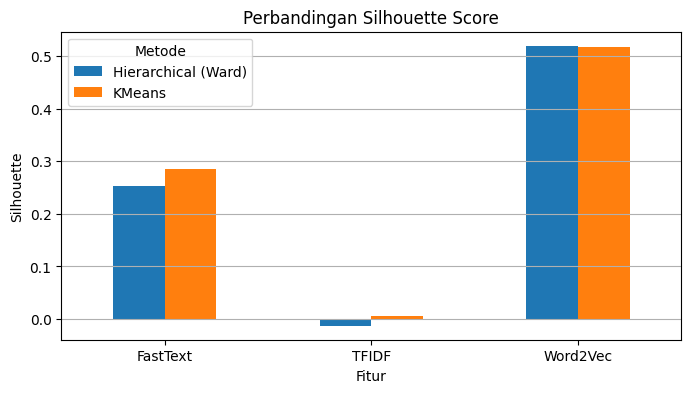

In [29]:
perbandingan = pd.concat([tabel_km, tabel_hc], ignore_index=True)
display(perbandingan.round(4).sort_values('Silhouette', ascending=False).reset_index(drop=True))

pivot = perbandingan.pivot(index='Fitur', columns='Metode', values='Silhouette')
pivot.plot(kind='bar', figsize=(8, 4))
plt.title('Perbandingan Silhouette Score')
plt.ylabel('Silhouette')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

Top words in each cluster (help interpret the cluster theme)

In [30]:
from collections import Counter

def kata_teratas(kolom_label, n=8):
    for c in sorted(df[kolom_label].unique()):
        teks = ' '.join(df[df[kolom_label] == c][KOLOM_TEKS]).split()
        top = [w for w, _ in Counter(teks).most_common(n)]
        print(f'Cluster {c} ({(df[kolom_label]==c).sum()} review): {top}')

for kolom in ['Kmeans_TFIDF', 'Kmeans_Word2Vec', 'Kmeans_FastText']:
    print('==', kolom)
    kata_teratas(kolom)
    print()

== Kmeans_TFIDF
Cluster 0 (1600 review): ['bahan', 'sesuai', 'nya', 'warna', 'tipis', 'bagus', 'baju', 'kirim']
Cluster 1 (195 review): ['bagus', 'sesuai', 'bahan', 'nyaman', 'nya', 'warna', 'harga', 'lembut']
Cluster 2 (203 review): ['banget', 'bagus', 'bahan', 'beli', 'tipis', 'nya', 'pas', 'adem']

== Kmeans_Word2Vec
Cluster 0 (644 review): ['bahan', 'bagus', 'nya', 'sesuai', 'tipis', 'banget', 'warna', 'harga']
Cluster 1 (989 review): ['bahan', 'bagus', 'sesuai', 'nya', 'banget', 'baju', 'warna', 'beli']
Cluster 2 (365 review): ['bagus', 'tipis', 'sesuai', 'baju', 'beli', 'banget', 'nya', 'kirim']

== Kmeans_FastText
Cluster 0 (649 review): ['bahan', 'bagus', 'tipis', 'nya', 'sesuai', 'nyaman', 'banget', 'adem']
Cluster 1 (808 review): ['sesuai', 'bagus', 'nya', 'warna', 'barang', 'kirim', 'harga', 'bahan']
Cluster 2 (541 review): ['nya', 'ukur', 'bagus', 'beli', 'baju', 'sesuai', 'banget', 'pas']



In [31]:
df.to_csv('hasil_clustering.csv', index=False)

## 6. Analisis




## 1. Number of Clusters

Based on the elbow plot, both Word2Vec and FastText show a significant decrease in inertia up to k = 3, after which the rate of decline slows down. Therefore, 3 clusters were selected for all three features to ensure a fair comparison. In contrast, the TF-IDF plot does not exhibit a clear "elbow" point, making it more difficult to determine an optimal number of clusters for this feature.

## 2. Comparison of Features

| Feature | Silhouette (KMeans) | Silhouette (Hierarchical) | Davies-Bouldin (KMeans / Hierarchical) |
|---|---:|---:|---:|
| TF-IDF | 0.0065 | -0.0127 | 5.9131 / 2.1499 |
| Word2Vec | 0.5166 | 0.5200 | 0.5995 / 0.5817 |
| FastText | 0.2847 | 0.2528 | 1.1821 / 1.2257 |

Word2Vec yielded the best clustering results based on both Silhouette and Davies-Bouldin scores. FastText ranked second, while TF-IDF produced the poorest results. The TF-IDF Silhouette scores approaching zero, or even becoming negative in the case of Hierarchical clustering indicate poor separation between clusters.

Furthermore, the cluster sizes for TF-IDF are highly imbalanced. KMeans produced clusters of 1600, 195, and 203 reviews, while Hierarchical clustering resulted in 1919, 55, and 24 reviews. Conversely, KMeans applied to FastText yielded a more balanced distribution: 649, 808, and 541 reviews.

These findings differ from the initial hypothesis that FastText would outperform Word2Vec. It is likely that the text preprocessing steps diminished the advantage FastText typically offers in recognizing variations in word spelling or formatting.

## 3. Comparison of Clustering Methods

The differences in results between KMeans and Hierarchical clustering are relatively minor. Hierarchical clustering performs slightly better with Word2Vec, while KMeans performs better with FastText and TF-IDF, based on Silhouette scores. In general, feature selection has a greater impact on clustering results than the choice of clustering method.

KMeans tends to produce more balanced clusters and is more practical for large datasets. Hierarchical clustering, meanwhile, allows for the visualization of relationships between groups via a dendrogram, though it is more computationally intensive.

## 4. Cluster Interpretation

Since most reviews concern clothing products, terms such as *bahan* (material), *bagus* (good), *sesuai* (as expected/appropriate), and *banget* (very/really) appear across various clusters. The most interpretable results are obtained using FastText combined with KMeans:

- **Cluster 0 (649 reviews):** Material comfort, characterized by terms like *bahan* (material), *tipis* (thin), *nyaman* (comfortable), *adem* (cool/breathable), and *kaos* (t-shirt).
- **Cluster 1 (808 reviews):** Transactions and shipping, characterized by terms like *barang* (item/product), *kirim* (shipping), *harga* (price), *pesan* (order), and *warna* (color).
- **Cluster 2 (541 reviews):** Sizing and fit, characterized by terms like *ukur* (size), *pas* (fit), *baju* (clothing), and *beli* (buy).

With Word2Vec, some clusters still contain overlapping terms. Meanwhile, TF-IDF produces one large cluster containing reviews with general themes, while the other two clusters focus primarily on material comfort and expressive language.

When compared against sentiment, the clusters do not clearly separate positive reviews from negative ones. For instance, Cluster 0 in the FastText model contains 325 negative reviews and 324 positive reviews. This indicates that the clustering reflects the topics being discussed such as material, shipping, and sizing rather than the sentiment of the reviews.

## 5. Conclusion

Based on the evaluation, the combination of Word2Vec and Hierarchical Ward clustering yields the best results, with a Silhouette score of 0.5200 and a Davies-Bouldin index of 0.5817. However, FastText combined with K-Means is easier to interpret, as it yields three fairly distinct themes: materials, shipping, and clothing size. Meanwhile, TF-IDF produces the least effective results.

This study has several limitations. Favorable evaluation scores do not necessarily indicate distinct cluster themes, as observed in the case of Word2Vec. Furthermore, the term "nya" (a possessive/referential suffix in Indonesian) appears frequently and could be considered a stopword. The choice of k = 3 also presents a limitation, given that the elbow plot for TF-IDF does not show a clear "elbow" point. Additionally, the interpretation of the themes remains dependent on the most frequently occurring words.
